# HW9: Latent Diffusion on Fashion-MNIST (DATA266)

Class-conditional latent diffusion model: pretrained `stabilityai/sd-vae-ft-mse` VAE + a U-Net denoiser trained with classifier-free guidance.

**Before running:** Runtime → Change runtime type → **T4 GPU**. Check `HW` in Cell 1 matches this assignment's folder.

**Design decisions**
- Images are resized from 28×28 to **256×256** and repeated to 3 channels, because this VAE expects RGB and downsamples by 8. That gives a **4×32×32** latent, so the U-Net levels are 32 → 16 → 8, with self-attention at 16×16 and at the 8×8 bottleneck as the spec requires.
- The VAE is pretrained and frozen. The second-model (HP_ID) requirement is waived for this assignment.
- The overview mentions cross-attention, but Section 3 specifies self-attention with label and time embeddings combined, so this notebook follows Section 3.
- Latents and resumable checkpoints go to Google Drive, outside the repo, because `git_commit_push` runs `git add .` and the latents are about 1 GB. If Colab disconnects, run all cells again and training resumes.

## Step 0: Session bootstrap and personal parameters

In [19]:
# Cell 1: session bootstrap
from google.colab import userdata
import sys, os, subprocess
TOKEN = userdata.get('GITHUB_TOKEN')
USERNAME = "vedika0806"
REPO = "data266-5937"
HW = "hw9"

os.system(f"git clone https://{TOKEN}@github.com/{USERNAME}/{REPO}.git /content/{REPO}")

sys.path.append(f"/content/{REPO}/common")
import colab_bootstrap
import importlib
importlib.reload(colab_bootstrap)   # force fresh reload, avoid stale cached module
from colab_bootstrap import setup_repo, get_logger, git_commit_push, git_tag_push

REPO_PATH = f"/content/{REPO}"
HW_PATH = setup_repo(HW, USERNAME, REPO, TOKEN)
logger = get_logger(HW_PATH)

logger.info(f"=== Session started for {HW} ===")
git_commit_push(REPO_PATH, f"{HW}: session start")

INFO:/content/data266-5937/hw9:=== Session started for hw9 ===


Working directory: /content/data266-5937/hw9
[main 34497f1] hw9: session start
 1 file changed, 2 insertions(+)
 


In [20]:
# Cell 2: personal parameters (Section 0.1)
SID4 = 5937
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")
logger.info(f"Params: SID4={SID4}, SEED={SEED}, SLICE={SLICE}, HP_ID={HP_ID}, CLS_A={CLS_A}, CLS_B={CLS_B}")

INFO:/content/data266-5937/hw9:Params: SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


SID4=5937, SEED=5937, SLICE=937, HP_ID=3, CLS_A=7, CLS_B=6


In [21]:
!pip install -q diffusers accelerate

In [6]:
# Cell 4: imports, seeding, device, Google Drive
import math, time, random, csv
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from diffusers import AutoencoderKL
import matplotlib.pyplot as plt
from google.colab import drive

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(SEED)
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "Switch the runtime to a GPU: Runtime > Change runtime type."
USE_AMP = device.type == "cuda"
print(torch.__version__, torch.cuda.get_device_name(0))

drive.mount("/content/drive")
STORE = f"/content/drive/MyDrive/data266_{HW}"
os.makedirs(STORE, exist_ok=True)

logger.info(f"Setup done, device={device}, seed={SEED}")

2.11.0+cu130 Tesla T4
Mounted at /content/drive


INFO:/content/data266-5937/hw9:Setup done, device=cuda, seed=5937


In [22]:
# Cell 5: configuration (values from the assignment unless marked as a choice)
IMG_SIZE       = 256
LATENT_CH      = 4
LATENT_SIZE    = IMG_SIZE // 8
VAE_ID         = "stabilityai/sd-vae-ft-mse"
SCALE          = 0.18215  # standard SD VAE latent scaling factor

T              = 1000
BETA_START     = 1e-4
BETA_END       = 0.02
VIS_TIMESTEPS  = [0, 250, 500, 750, 999]

BASE_CH        = 64
CH_MULT        = (1, 2, 4)
NUM_RES_BLOCKS = 2
ATTN_RES       = (16,)
NUM_CLASSES    = 10
NULL_LABEL     = NUM_CLASSES
P_UNCOND       = 0.1

EPOCHS         = 50
LR             = 2e-5
BATCH_SIZE     = 64
CKPT_EVERY     = 5
PUSH_EVERY     = 10

GUIDANCE_W     = 3.0
N_SAMPLES      = 64

CLASS_NAMES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]

LATENT_FILE = f"{STORE}/latents_train_{IMG_SIZE}.pt"
CKPT_FILE   = f"{STORE}/unet_latest.pt"
logger.info(f"Config: img={IMG_SIZE}, latent={LATENT_CH}x{LATENT_SIZE}x{LATENT_SIZE}, T={T}, "
            f"epochs={EPOCHS}, lr={LR}, batch={BATCH_SIZE}, w={GUIDANCE_W}")

INFO:/content/data266-5937/hw9:Config: img=256, latent=4x32x32, T=1000, epochs=50, lr=2e-05, batch=64, w=3.0


## Part 1: VAE compression and latent representation
Fashion-MNIST images become 3-channel 256×256 tensors in [-1, 1], which is what the VAE expects.

In [23]:
# Cell 6: Fashion-MNIST
transform = transforms.Compose([
    transforms.Resize(IMG_SIZE, interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.repeat(3, 1, 1)),   # 1 channel -> 3 channels
    transforms.Lambda(lambda x: x * 2.0 - 1.0),       # [0, 1] -> [-1, 1]
])
train_set = datasets.FashionMNIST("/content/data", train=True,  download=True, transform=transform)
test_set  = datasets.FashionMNIST("/content/data", train=False, download=True, transform=transform)

def to_gray(x):
    """[-1, 1] 3-channel batch -> [0, 1] single-channel numpy batch for plotting."""
    return ((x.clamp(-1, 1) + 1) / 2).mean(dim=1).detach().cpu().numpy()

print(len(train_set), "train,", len(test_set), "test, image shape", train_set[0][0].shape)
logger.info("Fashion-MNIST loaded")
git_commit_push(REPO_PATH, f"{HW}: data loaded")

INFO:/content/data266-5937/hw9:Fashion-MNIST loaded


60000 train, 10000 test, image shape torch.Size([3, 256, 256])
[main 8b19689] hw9: data loaded
 1 file changed, 3 insertions(+)
 


In [24]:
# Cell 7: load the pretrained VAE and freeze it
vae = AutoencoderKL.from_pretrained(VAE_ID).to(device).eval()
vae.requires_grad_(False)
assert abs(vae.config.scaling_factor - SCALE) < 1e-6
print("VAE parameters (millions):", round(sum(p.numel() for p in vae.parameters()) / 1e6, 1))

def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP)

@torch.no_grad()
def encode(x):
    """Images in [-1, 1] -> scaled latents z0. Uses the posterior mean so the cache is deterministic."""
    with autocast():
        z = vae.encode(x).latent_dist.mean
    return z.float() * SCALE

@torch.no_grad()
def decode(z, batch_size=32):
    """Scaled latents -> images in [-1, 1]. Undoes the scaling before decoding."""
    parts = []
    for chunk in z.split(batch_size):
        with autocast():
            parts.append(vae.decode(chunk / SCALE).sample.float())
    return torch.cat(parts)

logger.info(f"Loaded pretrained VAE {VAE_ID}, scaling factor {SCALE}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
INFO:/content/data266-5937/hw9:Loaded pretrained VAE stabilityai/sd-vae-ft-mse, scaling factor 0.18215


VAE parameters (millions): 83.7


Reconstruction MSE: 0.000125 on [-1, 1], 0.000031 on [0, 1]


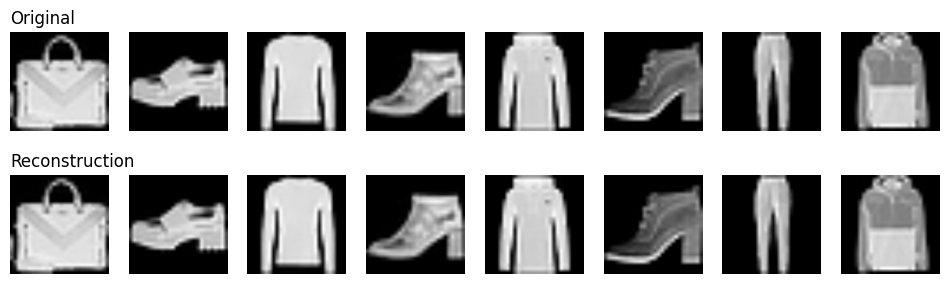

INFO:/content/data266-5937/hw9:VAE reconstruction MSE=0.000125 on [-1,1], 0.000031 on [0,1], 1000 test images


[main ed61aa2] hw9: VAE reconstruction check
 1 file changed, 2 insertions(+)
 


In [25]:
# Cell 8: verify reconstruction on 1,000 test images
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(test_set), generator=g)[:1000].tolist()
recon_loader = DataLoader(Subset(test_set, idx), batch_size=32, num_workers=2)

squared_error, pixels = 0.0, 0
for x, _ in recon_loader:
    x = x.to(device)
    x_hat = decode(encode(x)).clamp(-1, 1)
    squared_error += F.mse_loss(x_hat, x, reduction="sum").item()
    pixels += x.numel()

recon_mse = squared_error / pixels         # images in [-1, 1]
recon_mse_01 = recon_mse / 4               # same error on the [0, 1] scale
print(f"Reconstruction MSE: {recon_mse:.6f} on [-1, 1], {recon_mse_01:.6f} on [0, 1]")

x = x[:8]; x_hat = x_hat[:8]
orig, rec = to_gray(x), to_gray(x_hat)
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for i in range(8):
    axes[0, i].imshow(orig[i], cmap="gray", vmin=0, vmax=1); axes[0, i].axis("off")
    axes[1, i].imshow(rec[i],  cmap="gray", vmin=0, vmax=1); axes[1, i].axis("off")
axes[0, 0].set_title("Original", loc="left"); axes[1, 0].set_title("Reconstruction", loc="left")
plt.savefig(f"{HW_PATH}/p1_vae_reconstruction.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close()

logger.info(f"VAE reconstruction MSE={recon_mse:.6f} on [-1,1], {recon_mse_01:.6f} on [0,1], 1000 test images")
git_commit_push(REPO_PATH, f"{HW}: VAE reconstruction check")

In [26]:
# Cell 9: encode the training set once and cache it on Drive
if os.path.exists(LATENT_FILE):
    cache = torch.load(LATENT_FILE, map_location="cpu")
    train_z, train_y = cache["z"], cache["y"]
    print("Loaded cached latents")
else:
    loader = DataLoader(train_set, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
    zs, ys = [], []
    start = time.time()
    for i, (x, y) in enumerate(loader):
        zs.append(encode(x.to(device, non_blocking=True)).cpu()); ys.append(y)
        if i % 100 == 0:
            print(f"batch {i}/{len(loader)}, {time.time() - start:.0f}s")
    train_z, train_y = torch.cat(zs), torch.cat(ys)
    torch.save({"z": train_z, "y": train_y}, LATENT_FILE)
    logger.info(f"Encoded training set in {time.time() - start:.0f}s")

assert train_z.shape == (len(train_set), LATENT_CH, LATENT_SIZE, LATENT_SIZE)
latent_mean, latent_std = train_z.mean().item(), train_z.std().item()
print("Latents:", tuple(train_z.shape), f"mean={latent_mean:.4f}, std={latent_std:.4f}")

train_z, train_y = train_z.to(device), train_y.to(device)   # on the GPU, so batches are instant
logger.info(f"Latents ready: {tuple(train_z.shape)}, mean={latent_mean:.4f}, std={latent_std:.4f}")
git_commit_push(REPO_PATH, f"{HW}: training latents encoded")

Loaded cached latents
Latents: (60000, 4, 32, 32) mean=-0.0245, std=1.3606


INFO:/content/data266-5937/hw9:Latents ready: (60000, 4, 32, 32), mean=-0.0245, std=1.3606


[main 4cb8932] hw9: training latents encoded
 1 file changed, 1 insertion(+)
 


## Part 2: Forward diffusion in latent space
$q(z_t \mid z_0) = \mathcal{N}(z_t; \sqrt{\bar\alpha_t}\, z_0, (1-\bar\alpha_t)\mathbf{I})$, with $T = 1000$ and a linear schedule $\beta_t \in [10^{-4}, 0.02]$.

In [27]:
# Cell 10: noise schedule and noise injection
betas          = torch.linspace(BETA_START, BETA_END, T, device=device)
alphas         = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
alphas_cumprod_prev = torch.cat([torch.ones(1, device=device), alphas_cumprod[:-1]])

sqrt_ab   = torch.sqrt(alphas_cumprod)
sqrt_1mab = torch.sqrt(1.0 - alphas_cumprod)
posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)

def q_sample(z0, t, noise=None):
    """z_t = sqrt(abar_t) z0 + sqrt(1 - abar_t) eps"""
    if noise is None:
        noise = torch.randn_like(z0)
    return sqrt_ab[t].view(-1, 1, 1, 1) * z0 + sqrt_1mab[t].view(-1, 1, 1, 1) * noise

print(f"abar_0={alphas_cumprod[0]:.6f}, abar_{T-1}={alphas_cumprod[-1]:.6f}")

abar_0=0.999900, abar_999=0.000040


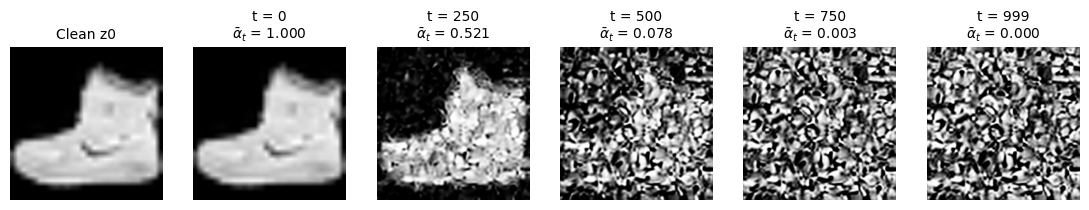

INFO:/content/data266-5937/hw9:Forward diffusion figure saved for t=[0, 250, 500, 750, 999]


[main f88db23] hw9: forward diffusion figure
 1 file changed, 1 insertion(+)
 


In [28]:
# Cell 11: decode noisy latents across timesteps
z0 = train_z[:1]
g = torch.Generator(device=device).manual_seed(SEED)
noise = torch.randn(z0.shape, generator=g, device=device)

panels = [("Clean z0", z0)]
for t in VIS_TIMESTEPS:
    tt = torch.tensor([t], device=device)
    panels.append((f"t = {t}\n" + r"$\bar\alpha_t$" + f" = {alphas_cumprod[t]:.3f}", q_sample(z0, tt, noise)))

fig, axes = plt.subplots(1, len(panels), figsize=(2.3 * len(panels), 2.9))
for ax, (title, z) in zip(axes, panels):
    ax.imshow(to_gray(decode(z))[0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10); ax.axis("off")
plt.savefig(f"{HW_PATH}/p2_forward_diffusion.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close()

logger.info(f"Forward diffusion figure saved for t={VIS_TIMESTEPS}")
git_commit_push(REPO_PATH, f"{HW}: forward diffusion figure")

## Part 3: Conditional denoising U-Net
Base channels 64 with multipliers (1, 2, 4), sinusoidal time embedding + MLP, residual blocks with GroupNorm and SiLU, self-attention at 16×16 and the bottleneck, and skip connections.
Label embeddings have 10 classes + 1 null label and are added to the time embedding.

In [29]:
# Cell 12: U-Net building blocks
def sinusoidal_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device, dtype=torch.float32) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, emb_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.emb_proj = nn.Linear(emb_dim, out_ch)
        self.norm2 = nn.GroupNorm(groups, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb_proj(F.silu(emb))[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class SelfAttention(nn.Module):
    def __init__(self, ch, heads=4, groups=8):
        super().__init__()
        assert ch % heads == 0
        self.heads = heads
        self.norm = nn.GroupNorm(groups, ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1)
        self.proj = nn.Conv2d(ch, ch, 1)

    def forward(self, x):
        b, c, h, w = x.shape
        q, k, v = self.qkv(self.norm(x)).chunk(3, dim=1)
        # (b, c, h, w) -> (b, heads, h*w, c/heads)
        q, k, v = [a.reshape(b, self.heads, c // self.heads, h * w).transpose(2, 3) for a in (q, k, v)]
        out = F.scaled_dot_product_attention(q, k, v)
        out = out.transpose(2, 3).reshape(b, c, h, w)
        return x + self.proj(out)

class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, stride=2, padding=1)
    def forward(self, x):
        return self.conv(x)

class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)
    def forward(self, x):
        return self.conv(F.interpolate(x, scale_factor=2, mode="nearest"))

In [30]:
# Cell 13: the U-Net
class LatentUNet(nn.Module):
    def __init__(self, in_ch=LATENT_CH, base=BASE_CH, ch_mult=CH_MULT, num_res=NUM_RES_BLOCKS,
                 attn_res=ATTN_RES, latent_size=LATENT_SIZE, num_classes=NUM_CLASSES):
        super().__init__()
        self.base = base
        emb_dim = base * 4
        self.time_mlp = nn.Sequential(nn.Linear(base, emb_dim), nn.SiLU(), nn.Linear(emb_dim, emb_dim))
        self.label_emb = nn.Embedding(num_classes + 1, emb_dim)     # 10 classes + 1 null label

        self.attn_layers_at = []     # records where attention was placed, for checking
        self.conv_in = nn.Conv2d(in_ch, base, 3, padding=1)

        # Encoder
        self.downs = nn.ModuleList()
        skips, ch, res = [base], base, latent_size
        for level, mult in enumerate(ch_mult):
            out_ch = base * mult
            for _ in range(num_res):
                block = nn.ModuleDict({"res": ResBlock(ch, out_ch, emb_dim)})
                if res in attn_res:
                    block["attn"] = SelfAttention(out_ch); self.attn_layers_at.append(("down", res))
                self.downs.append(block)
                ch = out_ch
                skips.append(ch)
            if level != len(ch_mult) - 1:
                self.downs.append(nn.ModuleDict({"down": Downsample(ch)}))
                skips.append(ch)
                res //= 2

        # Bottleneck
        self.mid1 = ResBlock(ch, ch, emb_dim)
        self.mid_attn = SelfAttention(ch); self.attn_layers_at.append(("mid", res))
        self.mid2 = ResBlock(ch, ch, emb_dim)

        # Decoder: one extra block per level consumes the skip from each downsample
        self.ups = nn.ModuleList()
        for level, mult in reversed(list(enumerate(ch_mult))):
            out_ch = base * mult
            for _ in range(num_res + 1):
                block = nn.ModuleDict({"res": ResBlock(ch + skips.pop(), out_ch, emb_dim)})
                if res in attn_res:
                    block["attn"] = SelfAttention(out_ch); self.attn_layers_at.append(("up", res))
                self.ups.append(block)
                ch = out_ch
            if level != 0:
                self.ups.append(nn.ModuleDict({"up": Upsample(ch)}))
                res *= 2
        assert not skips

        self.norm_out = nn.GroupNorm(8, ch)
        self.conv_out = nn.Conv2d(ch, in_ch, 3, padding=1)
        nn.init.zeros_(self.conv_out.weight); nn.init.zeros_(self.conv_out.bias)

    def forward(self, z, t, y):
        emb = self.time_mlp(sinusoidal_embedding(t, self.base)) + self.label_emb(y)   # combine time + label
        h = self.conv_in(z)
        skips = [h]
        for block in self.downs:
            if "down" in block:
                h = block["down"](h)
            else:
                h = block["res"](h, emb)
                if "attn" in block:
                    h = block["attn"](h)
            skips.append(h)

        h = self.mid2(self.mid_attn(self.mid1(h, emb)), emb)

        for block in self.ups:
            if "up" in block:
                h = block["up"](h)
            else:
                h = block["res"](torch.cat([h, skips.pop()], dim=1), emb)
                if "attn" in block:
                    h = block["attn"](h)
        return self.conv_out(F.silu(self.norm_out(h)))

In [31]:
# Cell 14: build the model and check it against the spec
set_seed(SEED)
model = LatentUNet().to(device)
n_params = sum(p.numel() for p in model.parameters())

check_z = torch.randn(2, LATENT_CH, LATENT_SIZE, LATENT_SIZE, device=device)
check_t = torch.randint(0, T, (2,), device=device)
check_y = torch.tensor([3, NULL_LABEL], device=device)
with torch.no_grad():
    assert model(check_z, check_t, check_y).shape == check_z.shape

assert model.label_emb.num_embeddings == 11
assert {r for _, r in model.attn_layers_at} == {16, 8}, "Attention must be at 16x16 and the 8x8 bottleneck"
print(f"Parameters: {n_params / 1e6:.2f} M")
print("Attention at (stage, resolution):", model.attn_layers_at)
logger.info(f"U-Net built: {n_params / 1e6:.2f} M params, attention at {model.attn_layers_at}")
git_commit_push(REPO_PATH, f"{HW}: U-Net built")

INFO:/content/data266-5937/hw9:U-Net built: 14.74 M params, attention at [('down', 16), ('down', 16), ('mid', 8), ('up', 16), ('up', 16), ('up', 16)]


Parameters: 14.74 M
Attention at (stage, resolution): [('down', 16), ('down', 16), ('mid', 8), ('up', 16), ('up', 16), ('up', 16)]
[main 7f99365] hw9: U-Net built
 1 file changed, 1 insertion(+)
 


## Part 4: Training
The model predicts the noise with an MSE loss, for 50 epochs at LR 2e-5. Each label is replaced with the null label with probability 0.1.
Checkpoints go to Drive, so running all cells after a disconnect resumes from the last save. Epoch 1 prints an estimate of the total time.

In [18]:
# Cell 15: training loop
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
loss_csv = f"{HW_PATH}/train_loss.csv"
losses, start_epoch = [], 0

def save_checkpoint(epoch):
    tmp = CKPT_FILE + ".tmp"
    torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scaler": scaler.state_dict(),
                "epoch": epoch, "losses": losses, "rng": torch.get_rng_state(),
                "rng_cuda": torch.cuda.get_rng_state_all()}, tmp)
    os.replace(tmp, CKPT_FILE)   # a disconnect mid-save cannot corrupt the last good checkpoint

if os.path.exists(CKPT_FILE):
    ckpt = torch.load(CKPT_FILE, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model"]); optimizer.load_state_dict(ckpt["optimizer"])
    scaler.load_state_dict(ckpt["scaler"])
    losses, start_epoch = ckpt["losses"], ckpt["epoch"] + 1
    torch.set_rng_state(ckpt["rng"].cpu()); torch.cuda.set_rng_state_all([r.cpu() for r in ckpt["rng_cuda"]])
    print(f"Resuming after epoch {ckpt['epoch'] + 1}")
    logger.info(f"Resumed training at epoch {start_epoch + 1}")

n_train = len(train_z)
steps_per_epoch = n_train // BATCH_SIZE
model.train()
for epoch in range(start_epoch, EPOCHS):
    epoch_start, total = time.time(), 0.0
    perm = torch.randperm(n_train, device=device)
    for step in range(steps_per_epoch):
        batch = perm[step * BATCH_SIZE : (step + 1) * BATCH_SIZE]
        z0, y = train_z[batch], train_y[batch]

        t = torch.randint(0, T, (BATCH_SIZE,), device=device)
        noise = torch.randn_like(z0)
        zt = q_sample(z0, t, noise)
        drop = torch.rand(BATCH_SIZE, device=device) < P_UNCOND
        y = y.masked_fill(drop, NULL_LABEL)                  # classifier-free guidance label dropout

        optimizer.zero_grad(set_to_none=True)
        with autocast():
            loss = F.mse_loss(model(zt, t, y), noise)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total += loss.item()

    avg, secs = total / steps_per_epoch, time.time() - epoch_start
    assert math.isfinite(avg), f"Loss became {avg} at epoch {epoch + 1}"
    losses.append(avg)
    print(f"Epoch {epoch + 1:3d}/{EPOCHS}  loss {avg:.5f}  {secs:.0f}s  "
          f"about {secs * (EPOCHS - epoch - 1) / 60:.0f} min left")
    logger.info(f"Epoch {epoch + 1}/{EPOCHS} loss={avg:.5f} time={secs:.0f}s")

    if (epoch + 1) % CKPT_EVERY == 0 or epoch + 1 == EPOCHS:
        save_checkpoint(epoch)
    if (epoch + 1) % PUSH_EVERY == 0:
        with open(loss_csv, "w", newline="") as f:
            w = csv.writer(f); w.writerow(["epoch", "loss"]); w.writerows(enumerate(losses, 1))
        git_commit_push(REPO_PATH, f"{HW}: trained through epoch {epoch + 1}")

model.eval()
logger.info(f"Training finished: final loss={losses[-1]:.5f}")

INFO:/content/data266-5937/hw9:Epoch 1/50 loss=0.44757 time=160s


Epoch   1/50  loss 0.44757  160s  about 131 min left


INFO:/content/data266-5937/hw9:Epoch 2/50 loss=0.11503 time=158s


Epoch   2/50  loss 0.11503  158s  about 126 min left


INFO:/content/data266-5937/hw9:Epoch 3/50 loss=0.08885 time=158s


Epoch   3/50  loss 0.08885  158s  about 124 min left


... (91 outputs left out)

Epoch  49/50  loss 0.04969  158s  about 3 min left


INFO:/content/data266-5937/hw9:Epoch 50/50 loss=0.05001 time=158s


Epoch  50/50  loss 0.05001  158s  about 0 min left
[main 2d0df92] hw9: trained through epoch 50
 2 files changed, 20 insertions(+)
 


INFO:/content/data266-5937/hw9:Training finished: final loss=0.05001


In [32]:
# Cell 15b: reload the finished model instead of running retraining
loss_csv = f"{HW_PATH}/train_loss.csv"
weights_file = f"{HW_PATH}/latent_unet.pt"

if os.path.exists(CKPT_FILE):
    ckpt = torch.load(CKPT_FILE, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model"])
    losses = ckpt["losses"]
    source = CKPT_FILE
elif os.path.exists(weights_file):
    model.load_state_dict(torch.load(weights_file, map_location=device))
    with open(loss_csv) as f:
        losses = [float(row["loss"]) for row in csv.DictReader(f)]
    source = weights_file
else:
    raise FileNotFoundError("No saved model found. Check that Drive is mounted and HW is correct.")

assert len(losses) == EPOCHS, f"Found {len(losses)} epochs, expected {EPOCHS}."
model.eval()

print(f"Loaded {source}")
print(f"Epochs: {len(losses)}, final loss: {losses[-1]:.5f}")
logger.info(f"Reloaded trained U-Net from {source} after runtime disconnect, {len(losses)} epochs")

INFO:/content/data266-5937/hw9:Reloaded trained U-Net from /content/drive/MyDrive/data266_hw9/unet_latest.pt after runtime disconnect, 50 epochs


Loaded /content/drive/MyDrive/data266_hw9/unet_latest.pt
Epochs: 50, final loss: 0.05001


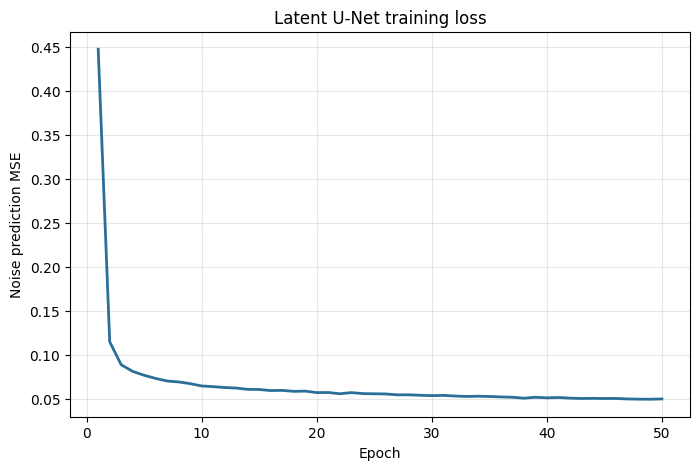

INFO:/content/data266-5937/hw9:Saved loss curve, loss CSV and final U-Net weights


56.3 MB
[main b87608a] hw9: training complete, loss curve and weights
 3 files changed, 2 insertions(+)
 create mode 100644 hw9/latent_unet.pt
 create mode 100644 hw9/p4_training_loss.png
 


In [33]:
# Cell 16: loss curve and final weights
with open(loss_csv, "w", newline="") as f:
    w = csv.writer(f); w.writerow(["epoch", "loss"]); w.writerows(enumerate(losses, 1))

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(losses) + 1), losses, color="#2a6f97", linewidth=2)
plt.xlabel("Epoch"); plt.ylabel("Noise prediction MSE")
plt.title("Latent U-Net training loss")
plt.grid(alpha=0.3)
plt.savefig(f"{HW_PATH}/p4_training_loss.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close()

torch.save(model.state_dict(), f"{HW_PATH}/latent_unet.pt")   # weights only, small enough for GitHub
print(round(os.path.getsize(f"{HW_PATH}/latent_unet.pt") / 2**20, 1), "MB")
logger.info("Saved loss curve, loss CSV and final U-Net weights")
git_commit_push(REPO_PATH, f"{HW}: training complete, loss curve and weights")

## Part 5: Sampling with classifier-free guidance
At every reverse step the model predicts noise twice, once with the label and once with the null label, and combines them as $\epsilon = (1+w)\epsilon_{cond} - w\,\epsilon_{uncond}$ with $w = 3$.
The DDPM sampler uses all 1,000 steps. The final latent is decoded by the VAE.

In [34]:
# Cell 17: DDPM sampler with classifier-free guidance
@torch.no_grad()
def sample(labels, w=GUIDANCE_W, seed=SEED):
    model.eval()
    n = len(labels)
    g = torch.Generator(device=device).manual_seed(seed)
    z = torch.randn(n, LATENT_CH, LATENT_SIZE, LATENT_SIZE, generator=g, device=device)
    null = torch.full((n,), NULL_LABEL, device=device)

    for i in reversed(range(T)):
        t = torch.full((n,), i, device=device)
        with autocast():
            eps_cond, eps_uncond = model(torch.cat([z, z]), torch.cat([t, t]),
                                         torch.cat([labels, null])).chunk(2)
        eps = ((1 + w) * eps_cond - w * eps_uncond).float()

        mean = (z - betas[i] / sqrt_1mab[i] * eps) / torch.sqrt(alphas[i])
        if i > 0:
            noise = torch.randn(z.shape, generator=g, device=device)
            z = mean + torch.sqrt(posterior_variance[i]) * noise
        else:
            z = mean
    return z

Labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3]
Sampling took 131s. Latent mean 0.013, std 1.379


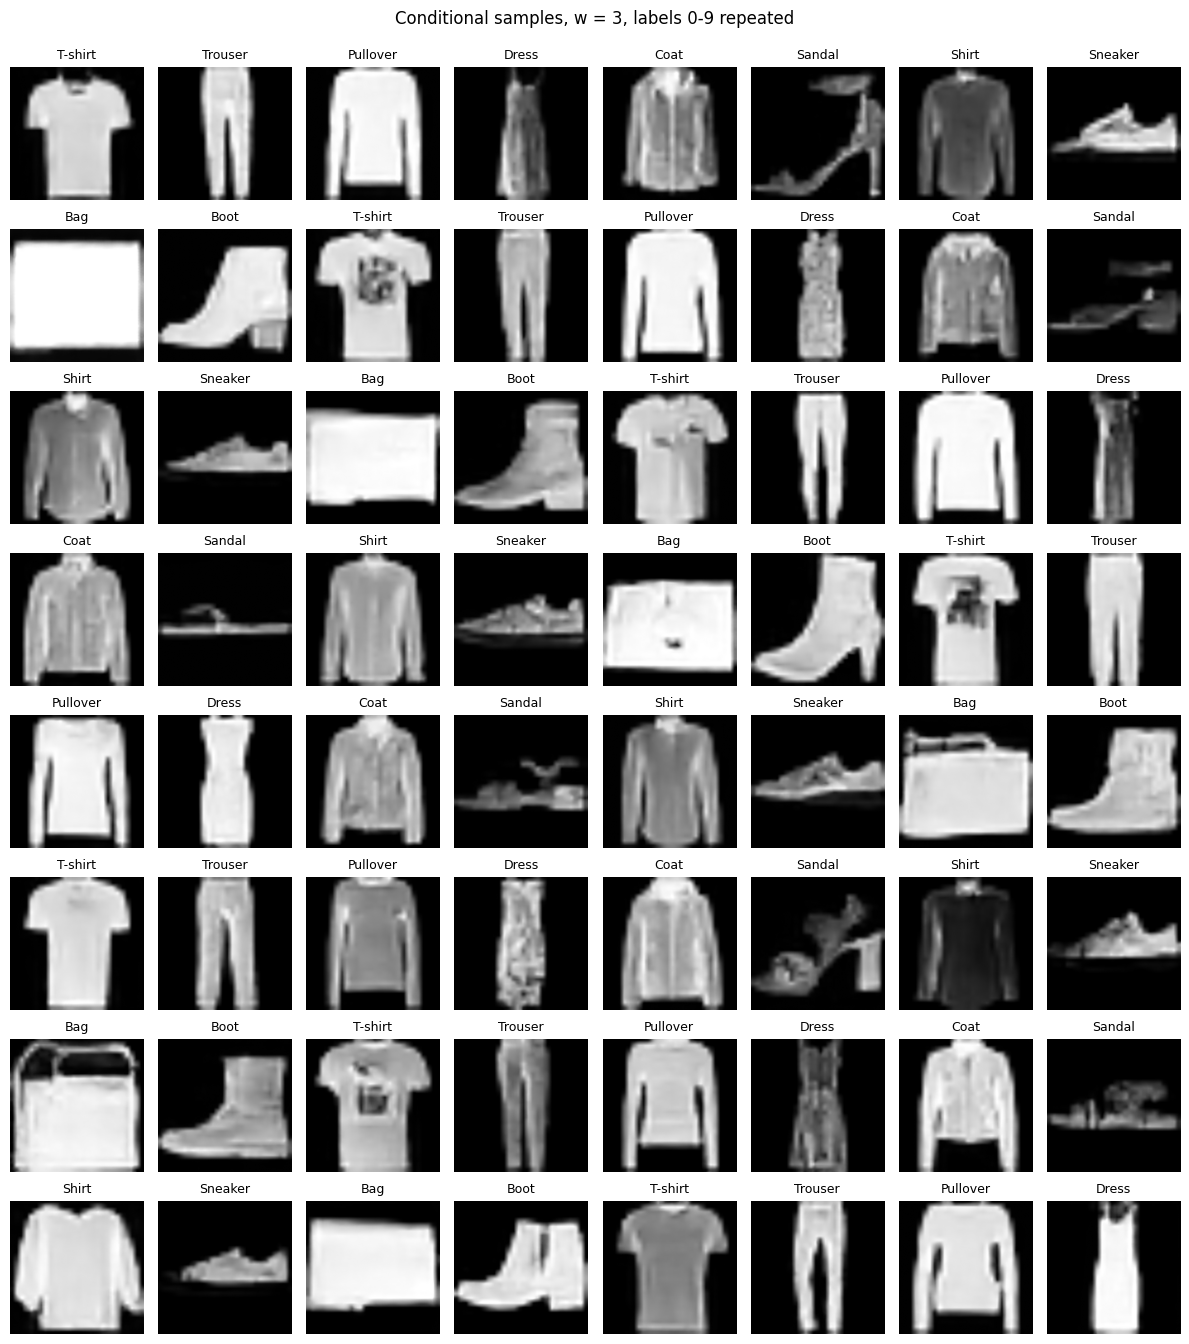

INFO:/content/data266-5937/hw9:Sampled 64 images with w=3.0 in 131s


953459 bytes
[main 872b65e] hw9: conditional sample grid
 2 files changed, 1 insertion(+)
 create mode 100644 hw9/p5_conditional_samples.png
 


In [35]:
# Cell 18: 64-image conditional grid, labels 0-9 repeated
labels = torch.arange(N_SAMPLES, device=device) % NUM_CLASSES
print("Labels:", labels.tolist())

start = time.time()
z_samples = sample(labels)
images = to_gray(decode(z_samples))
sample_secs = time.time() - start
print(f"Sampling took {sample_secs:.0f}s. Latent mean {z_samples.mean():.3f}, std {z_samples.std():.3f}")

fig, axes = plt.subplots(8, 8, figsize=(12, 13.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[labels[i].item()], fontsize=9); ax.axis("off")
fig.suptitle(f"Conditional samples, w = {GUIDANCE_W:g}, labels 0-9 repeated", y=0.995)
plt.tight_layout()
plt.savefig(f"{HW_PATH}/p5_conditional_samples.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close()

print(os.path.getsize(f"{HW_PATH}/p5_conditional_samples.png"), "bytes")
logger.info(f"Sampled {N_SAMPLES} images with w={GUIDANCE_W} in {sample_secs:.0f}s")
git_commit_push(REPO_PATH, f"{HW}: conditional sample grid")

## Reporting
Look at the figures, then write your analysis in Cell 19 and your AI use in Cell 20. Both cells refuse to save while `TODO` remains.

In [36]:
# Cell 19: METRICS.md (the results table fills itself in; the analysis is yours)
analysis = """
**VAE reconstruction.** On 1,000 test images, the reconstruction MSE was 0.000125 on the [-1, 1] scale, or
0.000031 on the [0, 1] scale. The reconstructions in p1_vae_reconstruction.png are almost indistinguishable from
the originals: garment shapes and fine details such as bag handles, shoe soles and hood outlines are preserved.
This shows that the 4x32x32 latent keeps enough information for diffusion to work in latent space, even though
the VAE was pretrained on natural images rather than Fashion-MNIST. It also means the softness of the generated
samples does not come mainly from VAE compression.

**Forward diffusion.** p2_forward_diffusion.png uses one image and the same noise at every timestep. At t = 0
(abar = 1.000) the decoded image looks the same as the clean one. At t = 250 (abar = 0.521) the boot's silhouette
is still recognizable, but its surface detail is lost and the background is corrupted. By t = 500 (abar = 0.078)
only a faint trace of the shape remains, and at t = 750 and t = 999 no trace is visible. The noise is added to the
latents rather than the pixels, so the decoded images show mottled, blob-like VAE artifacts rather than plain
per-pixel static. At t = 999, abar rounds to 0.000, so z_t is almost pure Gaussian noise. That is the starting
point the reverse process needs.

**Training.** The model trained for all 50 epochs (about 46,850 updates) at about 158 s per epoch, or roughly
2.2 hours on the GPU. Loss fell from 0.0572 at epoch 20 to 0.0500 at epoch 50. It was still falling slowly at
the end, with small fluctuations between epochs (0.0497 at epoch 49, 0.0500 at epoch 50). Training was not
fully converged at this low learning rate of 2e-5, so more epochs might bring a small improvement. The runtime
disconnected after training finished, so the final model was reloaded from the saved checkpoint for sampling.

**Conditional samples.** With guidance w = 3, all 64 samples in the grid are recognizable as their requested
class, which shows that label conditioning and classifier-free guidance are working. T-shirts, trousers, boots
and sneakers are the most consistent, with clear silhouettes and some variety, such as printed T-shirts and
both flat and heeled boots.

**Weaker classes.** Sandals are the weakest class: their thin straps give fragmented or blobby shapes in several
samples, probably because small structures are hard to preserve in a latent space that is downsampled 8 times.
Bags and some pullovers are often nearly solid white with little interior detail, and 3 of the 6 bags are
close to plain rectangles. This may be a saturation effect from the strong guidance, which pushes samples
toward high contrast. Shirts, pullovers and coats look similar to each other, which is expected because these
classes have similar shapes in Fashion-MNIST.

**Image sharpness.** Edges look soft. The source images are only 28x28 and were enlarged to 256x256 for the VAE,
so the higher resolution adds no real detail.

**Limitation.** This assessment is visual and based on 64 samples. No quantitative metric such as FID was computed.
"""

content = f"""
## HW9 Results: Latent Diffusion on Fashion-MNIST

| Item | Value |
|---|---|
| VAE | {VAE_ID} (pretrained, frozen) |
| Image size / latent shape | {IMG_SIZE}x{IMG_SIZE} / {LATENT_CH}x{LATENT_SIZE}x{LATENT_SIZE} |
| Latent scaling factor | {SCALE} |
| Scaled latent mean / std (train) | {latent_mean:.4f} / {latent_std:.4f} |
| Reconstruction MSE, 1,000 test images, [-1, 1] | {recon_mse:.6f} |
| Reconstruction MSE, 1,000 test images, [0, 1] | {recon_mse_01:.6f} |
| Diffusion | T={T}, linear beta {BETA_START} to {BETA_END} |
| U-Net | base {BASE_CH}, mult {CH_MULT}, attention at 16x16 + bottleneck, {n_params / 1e6:.2f} M params |
| Training | {EPOCHS} epochs, Adam, LR {LR}, batch {BATCH_SIZE}, label dropout {P_UNCOND} |
| Final training loss | {losses[-1]:.5f} |
| Sampling | DDPM {T} steps, guidance w={GUIDANCE_W:g}, {N_SAMPLES} images |

### Analysis
{analysis}
"""
metrics_path = f"{HW_PATH}/METRICS.md"
existing = open(metrics_path).read() if os.path.exists(metrics_path) else ""
assert "## HW9 Results" not in existing, "This section is already in METRICS.md."
with open(metrics_path, "a") as f:   # "a" = append
    f.write(content)

print(content)
logger.info("Added results and analysis to METRICS.md")
git_commit_push(REPO_PATH, f"{HW}: add results to METRICS.md")

INFO:/content/data266-5937/hw9:Added results and analysis to METRICS.md



## HW9 Results: Latent Diffusion on Fashion-MNIST

| Item | Value |
|---|---|
| VAE | stabilityai/sd-vae-ft-mse (pretrained, frozen) |
| Image size / latent shape | 256x256 / 4x32x32 |
| Latent scaling factor | 0.18215 |
| Scaled latent mean / std (train) | -0.0245 / 1.3606 |
| Reconstruction MSE, 1,000 test images, [-1, 1] | 0.000125 |
| Reconstruction MSE, 1,000 test images, [0, 1] | 0.000031 |
| Diffusion | T=1000, linear beta 0.0001 to 0.02 |
| U-Net | base 64, mult (1, 2, 4), attention at 16x16 + bottleneck, 14.74 M params |
| Training | 50 epochs, Adam, LR 2e-05, batch 64, label dropout 0.1 |
| Final training loss | 0.05001 |
| Sampling | DDPM 1000 steps, guidance w=3, 64 images |

### Analysis

**VAE reconstruction.** On 1,000 test images, the reconstruction MSE was 0.000125 on the [-1, 1] scale, or
0.000031 on the [0, 1] scale. The reconstructions in p1_vae_reconstruction.png are almost indistinguishable from
the originals: garment shapes and fine details such as bag handles, 

In [ ]:
# Cell 20: AI_USE.md (Section 0.5). Answer honestly, in your own words, with a real pasted error.
ai_use_content = """# AI_USE.md

## Which parts I used AI for and which I wrote myself
- I used AI to understand the U-Net design and the classifier-free guidance sampler and to understand the results I got.
## One specific wrong thing the AI produced (paste the actual output)
- Initially, it suggested no optimizer while training, which would have impacted the loss or made the training longer. I added the Adam optimizer for effective training and loss assessment.
## How I found out it was wrong
- I could not find any optimizer in the training suggestions whilst designing th it was suggesting and that is where I realized it was wrong.
"""
assert "TODO" not in ai_use_content, "Fill in AI_USE.md first."
with open(f"{HW_PATH}/AI_USE.md", "w") as f:
    f.write(ai_use_content)

logger.info("Created AI_USE.md")
git_commit_push(REPO_PATH, f"{HW}: add AI_USE.md")

## Final checklist
1. File → Save, so the Drive copy has all its outputs.
2. Run Cell 21 to copy the notebook into the repo. Change the path if your notebook has a different name.
3. Run Cell 22 and confirm that `git status` is clean and not ahead of origin.
4. Go through the checklist in Section 9 of the guide, then run Cell 23 to tag.

In [ ]:
# Cell 21: copy the executed notebook into the repo
import shutil
NB_SOURCE = "/content/drive/MyDrive/Colab Notebooks/hw9_data266_5937.ipynb"   # <-- check this path
shutil.copy(NB_SOURCE, f"{HW_PATH}/hw9_data266_5937.ipynb")
logger.info("Copied executed notebook into repo")
git_commit_push(REPO_PATH, f"{HW}: add executed notebook")

In [ ]:
# Cell 22: verify everything was pushed
!ls -la {HW_PATH}
!cd {REPO_PATH} && git log --oneline -5
!cd {REPO_PATH} && git status
!cat {HW_PATH}/METRICS.md
!tail -5 {HW_PATH}/RUN_LOG.txt

In [ ]:
# Cell 23: tag only after the checklist is confirmed (uncomment to run)
# git_tag_push(REPO_PATH, HW)